# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Lunas, Bryce Enrico
- _Student No._: 2024-01596
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="Figures/minimization_analysis.png" alt="Minimization Analysis Plot" width="100%">

Figure 1: A 2×2 grid illustrating the test functions alongside their computed local extrema (located via the golden-section search algorithm) in the upper row, and their respective first derivatives in the lower row.





### Report discussion

Using any ratio other than the golden ratio breaks the algorithm's self-scaling property, meaning the ratio of the subintervals will no longer remain invariant after an update step. This asymmetry leads to imbalanced subinterval reductions where subsequent steps shrink by unequal amounts. Consequently, the search loses its guaranteed optimal convergence rate and can become slower or less efficient.

### Other comments
Hirap, Sir. I wanna cry T__T


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Equation 5.91
def phi(x):
  return x**4 - 9 * x**3 + 25 * x**2 - 24 * x + 4

# Equation 5.145
def f(x):
  return (
      -x**5
      + 4 * x**4
      - 4 * x**3
      + (x**2) * np.exp(x)
      - 2 * x**2
      - 4 * x * np.exp(x)
      + 8 * x
      + 4 * np.exp(x)
      - 8
  )

# Golden Section
def golden(func, x0, x1, kmax=200, tol=1.0e-8):
  varphi = 0.5 * (1 + math.sqrt(5))  # Golden ratio phi
  for k in range(1, kmax):
    x2 = x0 + (x1 - x0) / (varphi + 1)
    x3 = x0 + (x1 - x0) * varphi / (varphi + 1)

    # If func(x3) < func(x2), minimum is in (x2, x1)
    if func(x3) < func(x2):
      x0 = x2
    else:
      x1 = x3  # Otherwise, minimum is in (0, x3)

    xnew = (x0 + x1) / 2
    xdiff = abs(x1 - x0)

    if xdiff < tol:
      break

  return xnew

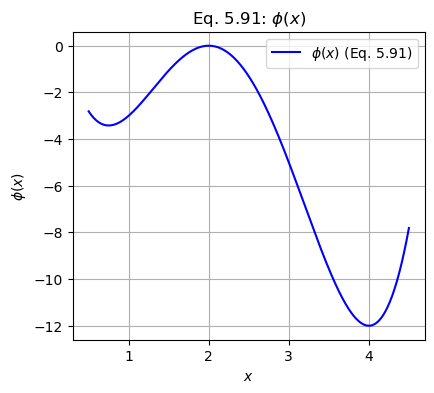

In [14]:
# Plot of Eq. 5.91
x_vals_1 = np.linspace(0.5, 4.5, 400)
y_vals_1 = phi(x_vals_1)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x_vals_1, y_vals_1, label="$\phi(x)$ (Eq. 5.91)", color="blue")
plt.title("Eq. 5.91: $\phi(x)$")
plt.xlabel("$x$")
plt.ylabel("$\phi(x)$")
plt.grid(True)
plt.legend()
plt.show()

In [3]:
# Finding Extrema for Eq. 5.91
min1_eq591 = golden_search(phi, 0.0, 1.2)

max_eq591 = golden_search(lambda x: -phi(x), 1.5, 2.5)

min2_eq591 = golden_search(phi, 3.5, 4.5)

print("--- Equation 5.91 Extrema ---")
print(f"Local Minimum 1: x = {min1_eq591:.6f}, phi(x) = {phi(min1_eq591):.6f}")
print(f"Local Maximum:   x = {max_eq591:.6f}, phi(x) = {phi(max_eq591):.6f}")
print(f"Local Minimum 2: x = {min2_eq591:.6f}, phi(x) = {phi(min2_eq591):.6f}")

--- Equation 5.91 Extrema ---
Local Minimum 1: x = 0.750000, phi(x) = -3.417969
Local Maximum:   x = 2.000000, phi(x) = 0.000000
Local Minimum 2: x = 4.000000, phi(x) = -12.000000


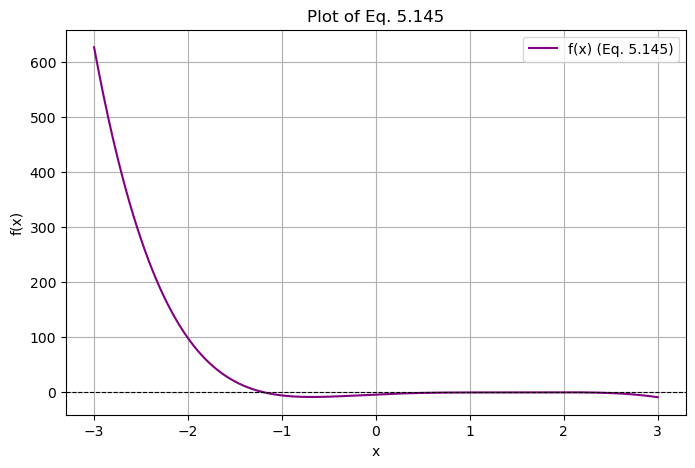

In [9]:
# Define Eq. 5.145
def f(x):
    return (
        -x**5
        + 4 * x**4
        - 4 * x**3
        + (x**2) * np.exp(x)
        - 2 * x**2
        - 4 * x * np.exp(x)
        + 8 * x
        + 4 * np.exp(x)
        - 8
    )

x_vals = np.linspace(-3, 3, 600)
y_vals = f(x_vals)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label="f(x) (Eq. 5.145)", color="purple")
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.title("Plot of Eq. 5.145")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()

In [11]:
def golden(func, x0, x1, kmax=200, tol=1.0e-8):
    varphi = 0.5 * (1 + math.sqrt(5))
    for k in range(1, kmax):
        x2 = x0 + (x1 - x0) / (varphi + 1)
        x3 = x0 + (x1 - x0) * varphi / (varphi + 1)
        
        if func(x3) < func(x2):
            x0 = x2
        else:
            x1 = x3
            
        xnew = (x0 + x1) / 2
        xdiff = abs(x1 - x0)
        
        if xdiff < tol:
            break
            
    return xnew
    
min_x = golden_search(f, -1.0, 0.0)
max_x = golden_search(lambda x: -f(x), 0.5, 1.5)

print(f"Computed Local Minimum: x = {min_x:.6f}, f(x) = {f(min_x):.6f}")
print(f"Computed Local Maximum: x = {max_x:.6f}, f(x) = {f(max_x):.6f}")

Computed Local Minimum: x = -0.679862, f(x) = -8.467698
Computed Local Maximum: x = 1.500000, f(x) = -0.223328


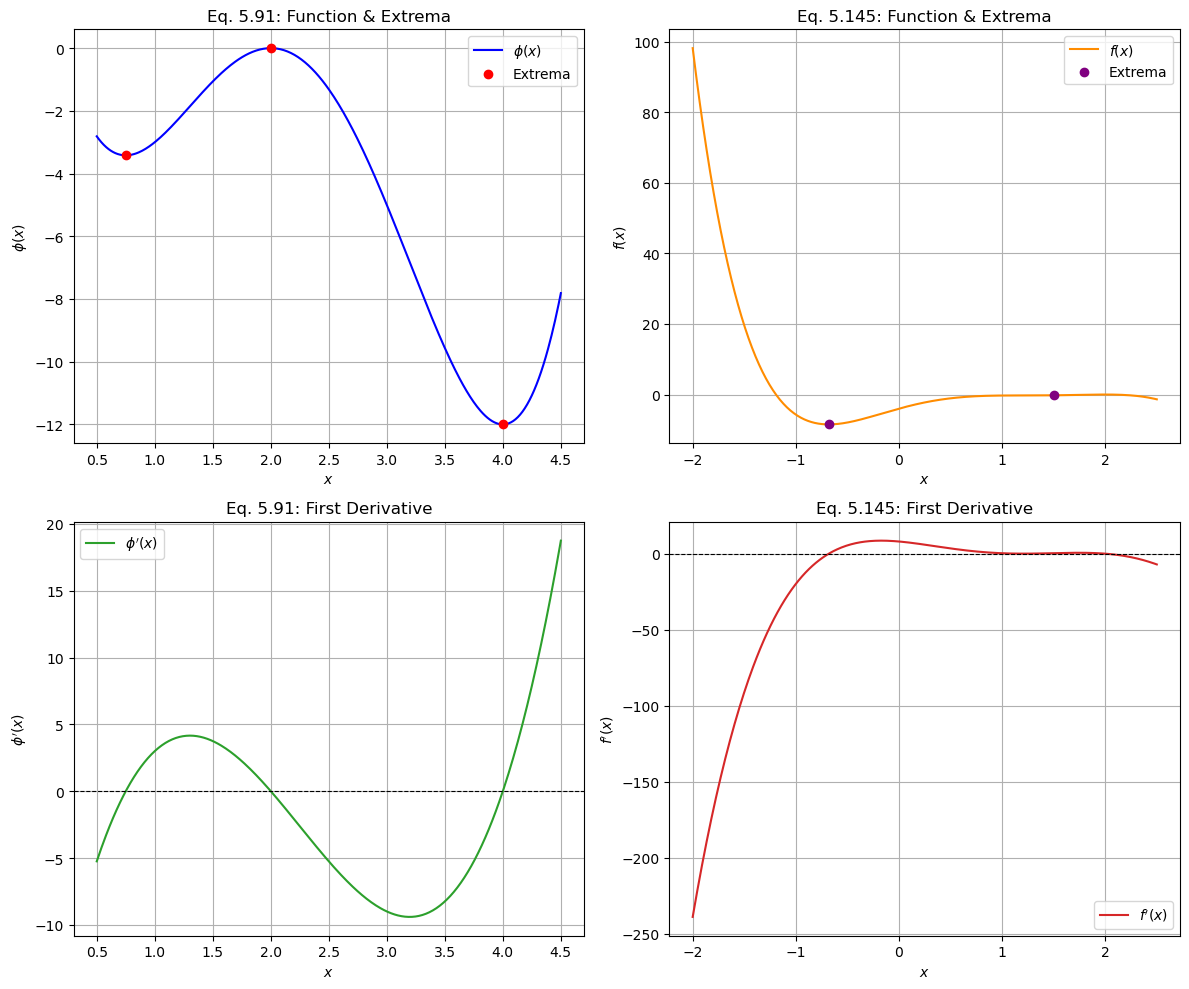

In [19]:
# Report Figure 
import math
import os
import matplotlib.pyplot as plt
import numpy as np

def phi(x):
  return x**4 - 9 * x**3 + 25 * x**2 - 24 * x + 4

def d_phi(x):
  return 4 * x**3 - 27 * x**2 + 50 * x - 24

def f(x):
  return (
      -x**5
      + 4 * x**4
      - 4 * x**3
      + (x**2) * np.exp(x)
      - 2 * x**2
      - 4 * x * np.exp(x)
      + 8 * x
      + 4 * np.exp(x)
      - 8
  )

def d_f(x):
  return (
      -5 * x**4
      + 16 * x**3
      - 12 * x**2
      + (x**2 + 2 * x) * np.exp(x)
      - 4 * x
      - (4 * x + 4) * np.exp(x)
      + 8
      + 4 * np.exp(x)
  )

# Golden Search
def golden_search(func, x0, x1, kmax=200, tol=1.0e-8):
  varphi = 0.5 * (1 + math.sqrt(5))
  for k in range(1, kmax):
    x2 = x0 + (x1 - x0) / (varphi + 1)
    x3 = x0 + (x1 - x0) * varphi / (varphi + 1)
    if func(x3) < func(x2):
      x0 = x2
    else:
      x1 = x3
    if abs(x1 - x0) < tol:
      break
  return (x0 + x1) / 2

ext1_x = golden_search(phi, 0.0, 1.2)
ext2_x = golden_search(lambda x: -phi(x), 1.5, 2.5)
ext3_x = golden_search(phi, 3.5, 4.5)
exts_591_x = [ext1_x, ext2_x, ext3_x]
exts_591_y = [phi(x) for x in exts_591_x]

f_min_x = golden_search(f, -1.5, -0.5)
f_max_x = golden_search(lambda x: -f(x), 0.5, 1.5)
exts_5145_x = [f_min_x, f_max_x]
exts_5145_y = [f(x) for x in exts_5145_x]

# Plotting Setup (2x2)
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

x_vals_1 = np.linspace(0.5, 4.5, 400)
x_vals_2 = np.linspace(-2.0, 2.5, 400)

# Eq. 5.91 
axs[0, 0].plot(
    x_vals_1, phi(x_vals_1), label="$\phi(x)$", color="blue", linewidth=1.5
)
axs[0, 0].scatter(
    exts_591_x,
    exts_591_y,
    color="red",
    zorder=5,
    label="Extrema",
    marker="o",
)
axs[0, 0].set_title("Eq. 5.91: Function & Extrema")
axs[0, 0].set_xlabel("$x$")
axs[0, 0].set_ylabel("$\phi(x)$")
axs[0, 0].grid(True)
axs[0, 0].legend()

# Eq. 5.145 
axs[0, 1].plot(
    x_vals_2, f(x_vals_2), label="$f(x)$", color="darkorange", linewidth=1.5
)
axs[0, 1].scatter(
    exts_5145_x,
    exts_5145_y,
    color="purple",
    zorder=5,
    label="Extrema",
    marker="o",
)
axs[0, 1].set_title("Eq. 5.145: Function & Extrema")
axs[0, 1].set_xlabel("$x$")
axs[0, 1].set_ylabel("$f(x)$")
axs[0, 1].grid(True)
axs[0, 1].legend()

# First Derivative of Eq. 5.91
axs[1, 0].plot(
    x_vals_1,
    d_phi(x_vals_1),
    label="$\phi'(x)$",
    color="tab:green",
    linewidth=1.5,
)
axs[1, 0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axs[1, 0].set_title("Eq. 5.91: First Derivative")
axs[1, 0].set_xlabel("$x$")
axs[1, 0].set_ylabel("$\phi'(x)$")
axs[1, 0].grid(True)
axs[1, 0].legend()

# First Derivative of Eq. 5.145
axs[1, 1].plot(
    x_vals_2,
    d_f(x_vals_2),
    label="$f'(x)$",
    color="tab:red",
    linewidth=1.5,
)
axs[1, 1].axhline(0, color="black", linestyle="--", linewidth=0.8)
axs[1, 1].set_title("Eq. 5.145: First Derivative")
axs[1, 1].set_xlabel("$x$")
axs[1, 1].set_ylabel("$f'(x)$")
axs[1, 1].grid(True)
axs[1, 1].legend()

plt.tight_layout()

os.makedirs("Figures", exist_ok=True)
plt.savefig(
    "Figures/minimization_analysis.png", dpi=300, bbox_inches="tight"
)
plt.show()

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

The code I wrote implements the derivative-free golden-section search algorithm to locate local extrema of scalar functions using only function values instead of derivatives. It uses the golden ratio (thank you, Gezerlis, for Section 5.5) to place intermediate test points, systematically narrowing down the search interval to ensure steady convergence.